# Canada Section 338 — Coverage, Incidence and Rate Impact

Analyzes the three Section 338 proclamations issued July 20, 2026 against Canada,
all effective **August 22, 2026** (originally August 19; deferred three days by Proclamation 11056 of August 18, 2026, after which negotiations failed) and all imposing a **50% additional duty**:

| Heading | Retaliates for | Basket |
|---|---|---|
| 9903.03.12 | Provincial liquor-board bans on U.S. alcohol | 63 codes |
| 9903.03.13 | Cheese tariff-rate-quota allocation | 52 codes |
| 9903.03.14 | Motor-vehicle tariffs and quotas | 439 codes |

Section 338 (19 U.S.C. §1338) is a dormant 1930 provision authorizing retaliatory
duties of up to 50% against a country that discriminates against U.S. commerce.
The three actions share a single U.S. note 51, which carves out goods already
subject to Section 232 (subdivision (c)) and civil aircraft meeting General Note 6
(subdivision (d)).

Note that the baskets deliberately target goods *other* than the offending sector —
the motor-vehicle action hits flowers, plywood, furniture and switchgear, not cars.

**This notebook analyzes the original Aug 22 baskets.** Later proclamations amended
them. From Sep 15, 2026 (Procs 11064 and 11065) the alcohol and autos baskets were
reshuffled and stack on top of Section 232. From Oct 30, 2026 (Proclamation of
Oct 23, 2026) the autos basket changed again. The timeline in Section 1 shows those
steps. Sections 2–6 describe the Aug 22 baskets, in force Aug 22 – Sep 14.
Section 7 shows what the Sep 15 carve-out change did and which products it reached;
Section 8 shows which goods' tariffs fell and which are new on Oct 30.
The README covers the amendments.

**Generates:** `figures/canada-338-*.pdf/png`

**Run after** `make-tariff-by-country-by-time.ipynb` — reads
[country-by-time.csv](country-by-time.csv) and imports the tariff engine directly
from that notebook, so there is no duplicated copy of the masks or the registry.

In [1]:
import json
import io
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import os

In [2]:
figfile = "./figures/"
os.makedirs(figfile, exist_ok=True)

plt.rcParams.update({
    'axes.spines.top':   False,
    'axes.spines.right': False,
    'axes.linewidth':    2,
    'axes.labelweight':  'bold',
    'axes.titleweight':  'bold',
    'axes.titlesize':    18,
    'axes.labelsize':    16,
    'xtick.labelsize':   12,
    'ytick.labelsize':   12,
    'legend.frameon':    False,
    'legend.fontsize':   12,
    'grid.alpha':        0.3,
    'grid.linestyle':    '--',
    'savefig.bbox':      'tight',
})

PALETTE = {
    'aggregate':  'black',
    'primary':    'darkblue',
    'secondary':  '#8B0000',
    'tertiary':   'darkgreen',
    'rank1':      '#2E5090',
    'rank2':      '#4A90E2',
    'rank3':      '#7CB9E8',
}

CANADA = "1220"

# Import-weight year. Set separately here because it is defined in the main
# notebook's panel-construction cell, which runs after the engine cells loaded
# below — keep it in sync with WEIGHT_YEAR there.
WEIGHT_YEAR = 2024

## Load the tariff engine

Rather than keeping a second copy of the masks and action registry, execute the
main notebook's code cells in order and stop once `tariff_imports` is defined.
This runs the data loaders, product lists, masks, apply functions, and the
registry — but not the panel-construction loop that follows.

In [3]:
_nb = json.load(io.open('make-tariff-by-country-by-time.ipynb', encoding='utf-8'))

for _cell in _nb['cells']:
    if _cell['cell_type'] != 'code':
        continue
    _src = ''.join(_cell['source'])
    exec(compile(_src, 'tariff-engine', 'exec'))
    if 'def tariff_imports' in _src:
        break

_s338 = [r for r in STACKED_REGIMES if r['authority'] == 'Section 338']
print(f"engine loaded — {len(TARIFF_ACTIONS)} tariff actions, "
      f"{len(_s338)} Section 338 regimes")

engine loaded — 89 tariff actions, 6 Section 338 regimes


## Section 1 — Canada's effective tariff over time

`country-by-time.csv` holds the import-weighted effective rate for each
country-date. Rates are the *policy-added* duty and exclude the pre-existing MFN
baseline, so the national average is shown net of the 2.3pp baseline that the
main notebook adds back for the published series.

Canada's line is flat from April through July: the Section 122 surcharge exempted
USMCA-compliant goods, so its lapse on July 23 leaves Canada unchanged. The
Section 338 actions are the first move in Canada's rate since the April metals
restructuring. The two later steps, Sep 15 and Oct 30, are the basket amendments
described above.

In [4]:
panel = pd.read_csv('country-by-time.csv', parse_dates=['date'])

canada = (panel[panel['country_name'] == 'CANADA']
          .set_index('date')['effective tariff']
          .sort_index())

national = (pd.read_csv('daily-tariff-latest-data.csv', parse_dates=['date'])
            .set_index('date')['import_weighted_avg_tariff'] - 2.3)

# Forward-fill Canada from policy dates to a daily series.
days = pd.date_range('2025-01-01', '2026-12-31', freq='D')
canada_daily = canada.reindex(days.union(canada.index)).ffill().fillna(0.0).reindex(days)
national_daily = national.reindex(days).ffill()

STEP = pd.Timestamp('2026-08-22')
print(f"Canada before Aug 22 : {canada_daily.loc['2026-08-21']:.3f}%")
print(f"Canada after  Aug 22 : {canada_daily.loc[STEP]:.3f}%")
print(f"step                 : +{canada_daily.loc[STEP] - canada_daily.loc['2026-08-18']:.3f}pp")

# Later steps: the basket amendments.
AMENDMENTS = [pd.Timestamp('2026-09-15'), pd.Timestamp('2026-10-30')]
for d in AMENDMENTS:
    print(f"Canada from {d:%b %d}   : {canada_daily.loc[d]:.3f}%  "
          f"(+{canada_daily.loc[d] - canada_daily.loc[d - pd.Timedelta(days=1)]:.3f}pp)")

Canada before Aug 22 : 5.817%
Canada after  Aug 22 : 7.665%
step                 : +1.848pp
Canada from Sep 15   : 7.942%  (+0.277pp)
Canada from Oct 30   : 7.966%  (+0.025pp)


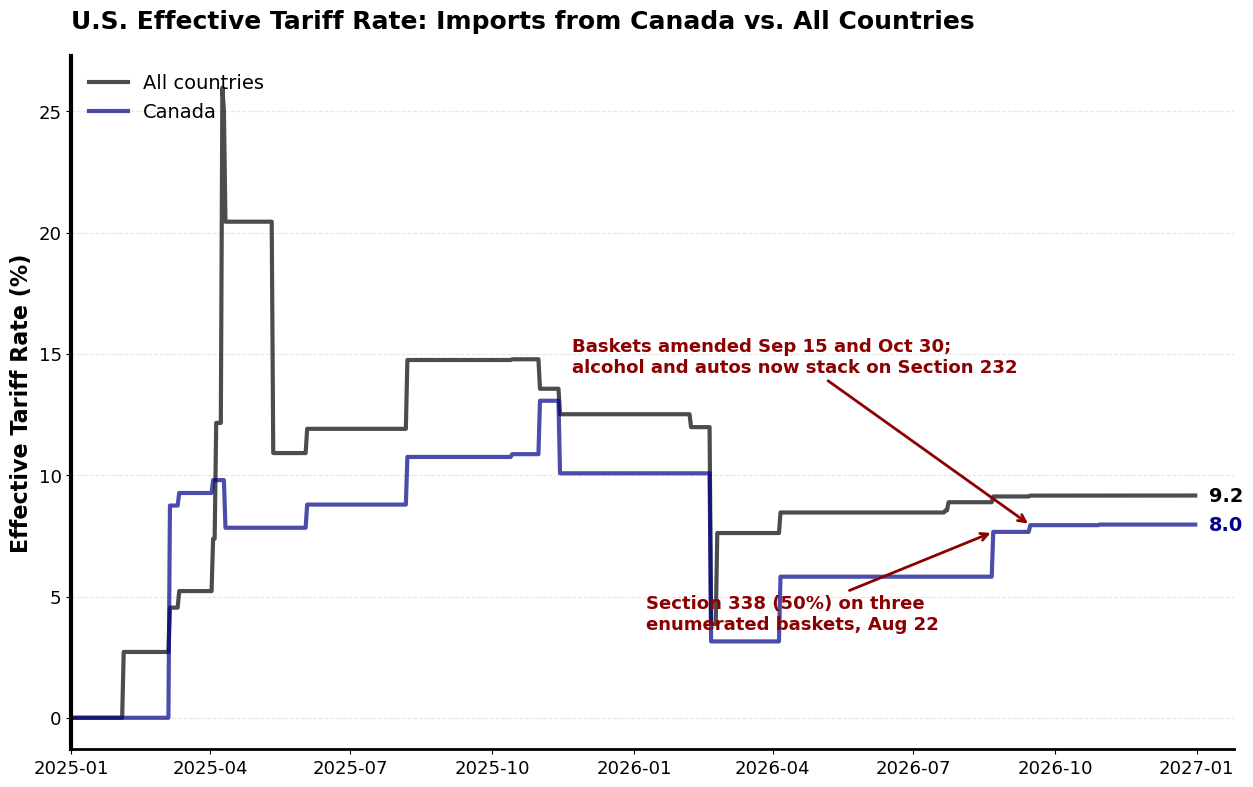

In [5]:
fig, ax = plt.subplots(figsize=(15, 9))

ax.plot(national_daily.index, national_daily.values,
        color=PALETTE['aggregate'], linewidth=3, alpha=0.7,
        label='All countries')
ax.plot(canada_daily.index, canada_daily.values,
        color=PALETTE['primary'], linewidth=3, alpha=0.7,
        label='Canada')

ax.annotate('Section 338 (50%) on three\nenumerated baskets, Aug 22',
            xy=(STEP, canada_daily.loc[STEP]),
            xytext=(-250, -70), textcoords='offset points',
            fontsize=13, fontweight='bold', color=PALETTE['secondary'],
            arrowprops=dict(arrowstyle='->', color=PALETTE['secondary'], linewidth=2))

ax.annotate('Baskets amended Sep 15 and Oct 30;\nalcohol and autos now stack on Section 232',
            xy=(AMENDMENTS[0], canada_daily.loc[AMENDMENTS[0]]),
            xytext=(-330, 110), textcoords='offset points',
            fontsize=13, fontweight='bold', color=PALETTE['secondary'],
            arrowprops=dict(arrowstyle='->', color=PALETTE['secondary'], linewidth=2))

for series, color in [(canada_daily, PALETTE['primary']),
                      (national_daily, PALETTE['aggregate'])]:
    ax.annotate(f'{series.iloc[-1]:.1f}',
                xy=(series.index[-1], series.iloc[-1]),
                xytext=(10, 0), textcoords='offset points',
                fontsize=14, fontweight='bold', color=color, va='center')

ax.set_ylabel('Effective Tariff Rate (%)', fontsize=16, fontweight='bold')
ax.set_title('U.S. Effective Tariff Rate: Imports from Canada vs. All Countries',
             fontsize=18, fontweight='bold', pad=20, loc='left')
ax.set_xlim([pd.Timestamp('2025-01-01'), pd.Timestamp('2027-01-25')])
ax.spines['left'].set_linewidth(3)
ax.spines['bottom'].set_linewidth(2)
ax.grid(axis='y', alpha=0.3, linestyle='--')
ax.tick_params(axis='both', labelsize=13)
ax.legend(fontsize=14, loc='upper left')

plt.savefig(figfile + 'canada-338-timeline.png', bbox_inches='tight')
plt.savefig(figfile + 'canada-338-timeline.pdf', bbox_inches='tight')
plt.show()

## Section 2 — What is hit, and what is not

Section 338 is **inclusion-scoped**: unlike the Brazil Section 301 action, which
covered all goods of the country minus an exemption list, these proclamations
reach only the codes enumerated in their annexes. So the dominant reason a good
escapes the duty is simply that it is *not on any list*.

Every HS10 line of U.S. imports from Canada is assigned to exactly one channel.
Exemptions are applied in the order U.S. note 51 presents them — subdivision (c)
(Section 232) before subdivision (d) (civil aircraft) — so a code on both lists
is attributed to Section 232.

In [6]:
imports = load_imports(CANADA, year=WEIGHT_YEAR)
total_imports = imports['imports'].sum()

BASKETS = ['alcohol', 'dairy', 'autos']
basket_masks = {b: _mask_stacked_include(imports, f'Canada-338-{b}') for b in BASKETS}
in_scope = basket_masks['alcohol'] | basket_masks['dairy'] | basket_masks['autos']

# Note 51(c): goods already subject to Section 232, except those removed from 232
# scope by the Apr 6, 2026 metals Annex II.
mask_232 = _mask_all_232(imports) & ~_mask_annex_II_removed(imports)
# Note 51(d): civil aircraft meeting General Note 6.
mask_air = _mask_stacked_exempt(imports, 'Canada-338-aircraft')

channel = pd.Series('Pays 50%', index=imports.index)
channel[~in_scope] = 'Not listed\n(out of scope)'
channel[in_scope & mask_232] = 'Section 232 goods\nnote 51(c)'
channel[in_scope & ~mask_232 & mask_air] = 'Civil aircraft\nnote 51(d)'

coverage = 100 * imports.groupby(channel)['share'].sum()
order = ['Pays 50%', 'Not listed\n(out of scope)',
         'Civil aircraft\nnote 51(d)', 'Section 232 goods\nnote 51(c)']
coverage = coverage.reindex(order).fillna(0.0)

dutied = channel == 'Pays 50%'
print(f"Total {WEIGHT_YEAR} U.S. imports from Canada : ${total_imports/1e9:.1f}B")
print(f"In at least one Section 338 basket    : {100*imports.loc[in_scope,'share'].sum():.2f}%")
print(f"Actually dutied                       : {100*imports.loc[dutied,'share'].sum():.2f}%"
      f"  (${imports.loc[dutied,'imports'].sum()/1e9:.2f}B)")
coverage.round(2).to_frame('share of imports (%)')

Total 2024 U.S. imports from Canada : $411.7B
In at least one Section 338 basket    : 4.97%
Actually dutied                       : 3.70%  ($15.21B)


,share of imports (%)
Pays 50%,3.70
Not listed\n(out of scope),95.03
Civil aircraft\nnote 51(d),0.88
Section 232 goods\nnote 51(c),0.40


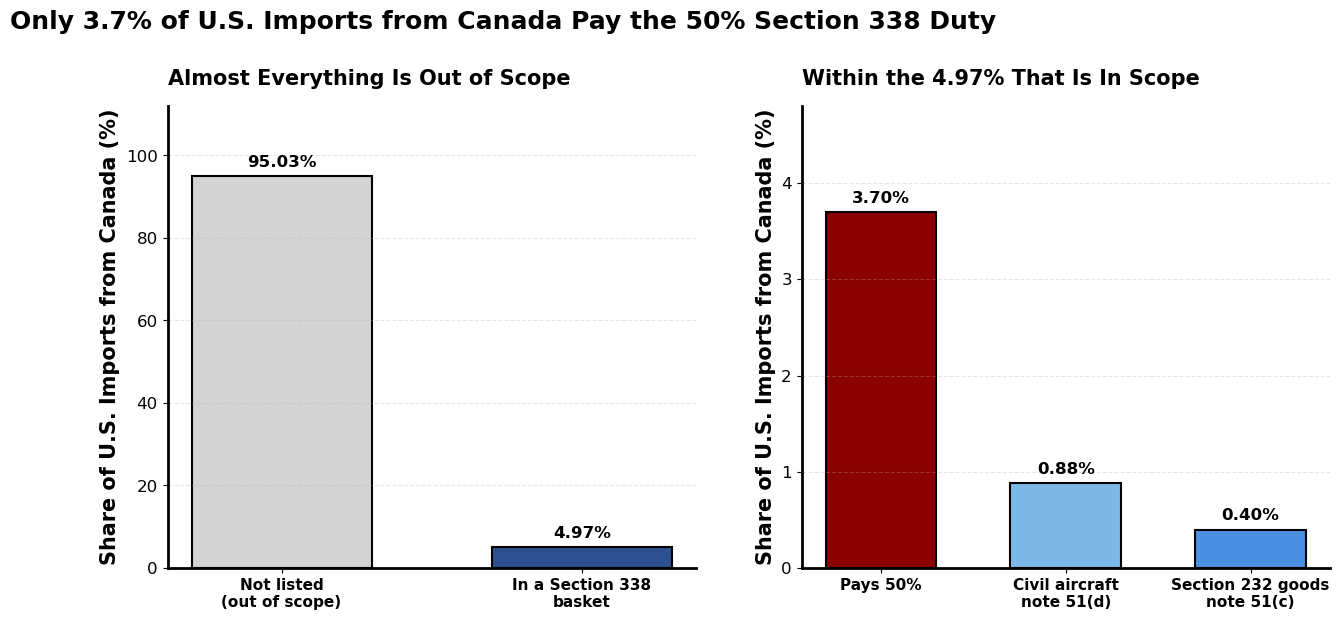

In [7]:
# Two panels: the in-scope share is so small that plotting it beside the 95%
# out-of-scope bar would flatten the three channels that matter. Panel A gives
# the headline split, panel B rescales to the 4.97% that is in scope.
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 6))

scope = pd.Series({'Not listed\n(out of scope)': coverage['Not listed\n(out of scope)'],
                   'In a Section 338\nbasket': 100 - coverage['Not listed\n(out of scope)']})

b1 = ax1.bar(range(2), scope.values, 0.6,
             color=['#D3D3D3', PALETTE['rank1']], edgecolor='black', linewidth=1.5)
for bar in b1:
    ax1.text(bar.get_x() + bar.get_width() / 2, bar.get_height() + 1.5,
             f'{bar.get_height():.2f}%', ha='center', va='bottom',
             fontsize=12, fontweight='bold')
ax1.set_xticks(range(2))
ax1.set_xticklabels(scope.index, fontsize=11)
ax1.set_ylabel('Share of U.S. Imports from Canada (%)', fontsize=15, fontweight='bold')
ax1.set_title('Almost Everything Is Out of Scope', fontsize=15, pad=15, loc='left')
ax1.set_ylim([0, 112])

inner = coverage.drop('Not listed\n(out of scope)')
b2 = ax2.bar(range(len(inner)), inner.values, 0.6,
             color=[PALETTE['secondary'], PALETTE['rank3'], PALETTE['rank2']],
             edgecolor='black', linewidth=1.5)
for bar in b2:
    ax2.text(bar.get_x() + bar.get_width() / 2, bar.get_height() + 0.07,
             f'{bar.get_height():.2f}%', ha='center', va='bottom',
             fontsize=12, fontweight='bold')
ax2.set_xticks(range(len(inner)))
ax2.set_xticklabels(inner.index, fontsize=11)
ax2.set_ylabel('Share of U.S. Imports from Canada (%)', fontsize=15, fontweight='bold')
ax2.set_title('Within the 4.97% That Is In Scope', fontsize=15, pad=15, loc='left')
ax2.set_ylim([0, inner.max() * 1.3])

for ax in (ax1, ax2):
    for label in ax.get_xticklabels():
        label.set_fontweight('bold')
    ax.spines['left'].set_linewidth(2)
    ax.spines['bottom'].set_linewidth(2)
    ax.grid(axis='y', alpha=0.3, linestyle='--')

fig.suptitle('Only 3.7% of U.S. Imports from Canada Pay the 50% Section 338 Duty',
             fontsize=18, fontweight='bold', x=0.02, ha='left', y=1.04)

plt.savefig(figfile + 'canada-338-coverage.png', bbox_inches='tight')
plt.savefig(figfile + 'canada-338-coverage.pdf', bbox_inches='tight')
plt.show()

## Section 3 — The three baskets side by side

The motor-vehicle basket is the whole story: it carries 94% of the dutied value.
Alcohol and dairy are, in trade terms, rounding error — the dairy action covers
$0.1B, and 13 of its 52 codes are tariff-rate-quota tier lines that carry no
trade at all.

The baskets are disjoint by construction, so these rows sum without
double-counting.

In [8]:
rows = []
for b in BASKETS:
    m = basket_masks[b]
    d = m & dutied
    rows.append({
        'basket': b,
        'codes': int(pd.read_csv(f'./tariff-lists/canada-338-{b}.csv',
                                 dtype={'HTSUS': str}).shape[0]),
        'in-scope $B': imports.loc[m, 'imports'].sum() / 1e9,
        'dutied $B': imports.loc[d, 'imports'].sum() / 1e9,
        'carved out $B': imports.loc[m & ~dutied, 'imports'].sum() / 1e9,
        'rate impact (pp)': 50 * imports.loc[d, 'imports'].sum() / total_imports,
    })

by_basket = pd.DataFrame(rows).set_index('basket')
by_basket.loc['TOTAL'] = by_basket.sum()
by_basket.round(3)

,codes,in-scope $B,dutied $B,carved out $B,rate impact (pp)
basket,,,,,
alcohol,63.0,1.001,1.001,0.000,0.122
dairy,52.0,0.097,0.097,0.000,0.012
autos,439.0,19.359,14.114,5.245,1.714
TOTAL,554.0,20.458,15.212,5.245,1.848


## Section 4 — Top products actually hit

Ranked by dutied import value. The list is a fair picture of what a Section 338
retaliation basket looks like in practice: construction and packaging materials,
furniture, consumer goods and industrial equipment — chosen for political
salience rather than any connection to autos, dairy or alcohol.

In [9]:
top = (imports[dutied]
       .groupby(['HS8', 'I_COMMODITY_SDESC'])['imports'].sum()
       .sort_values(ascending=False)
       .head(15)
       .reset_index())
top['$M'] = (top['imports'] / 1e6).round(0)
top['% of dutied'] = (100 * top['imports'] / imports.loc[dutied, 'imports'].sum()).round(2)
top['basket'] = [
    next(b for b in BASKETS
         if h in set(pd.read_csv(f'./tariff-lists/canada-338-{b}.csv',
                                 dtype={'HTSUS': str})['HTSUS']))
    for h in top['HS8']
]
top[['HS8', 'I_COMMODITY_SDESC', 'basket', '$M', '% of dutied']]

,HS8,I_COMMODITY_SDESC,basket,$M,% of dutied
0,94019910,"SEAT PARTS OF A KIND USED FOR MOTOR VEHICLES,N...",autos,570.0,3.75
1,25232900,PORTLAND CEMENT NESOI,autos,421.0,2.77
2,39232100,"SACKS AND BAGS OF POLYMERS OF ETHYLENE, NESOI",autos,418.0,2.75
3,94036080,"WOODEN FURNITURE, NESOI",autos,393.0,2.58
4,85437098,"ELECTRICAL MACHINES AND APPARATUS, NESOI",autos,372.0,2.44
5,22087000,LIQUEURS & CORDIALS IN CNTRS NT OVER 4 LITERS,alcohol,354.0,2.33
6,39233000,"CARBOYS, BOTTLE, FLASKS & SIMILAR ARTICLES, NESOI",autos,328.0,2.15
7,33059000,"PREPARATIONS FOR USE ON THE HAIR, NESOI",autos,283.0,1.86
8,39235000,"STOPPERS,LIDS,CAPS,& OTHER CLOSURES,OF PLASTIC",autos,271.0,1.78
9,48109212,PAPER/BOARD GT 150 G/M2 ROLLS CLY CTD MLTPLY N...,autos,259.0,1.70


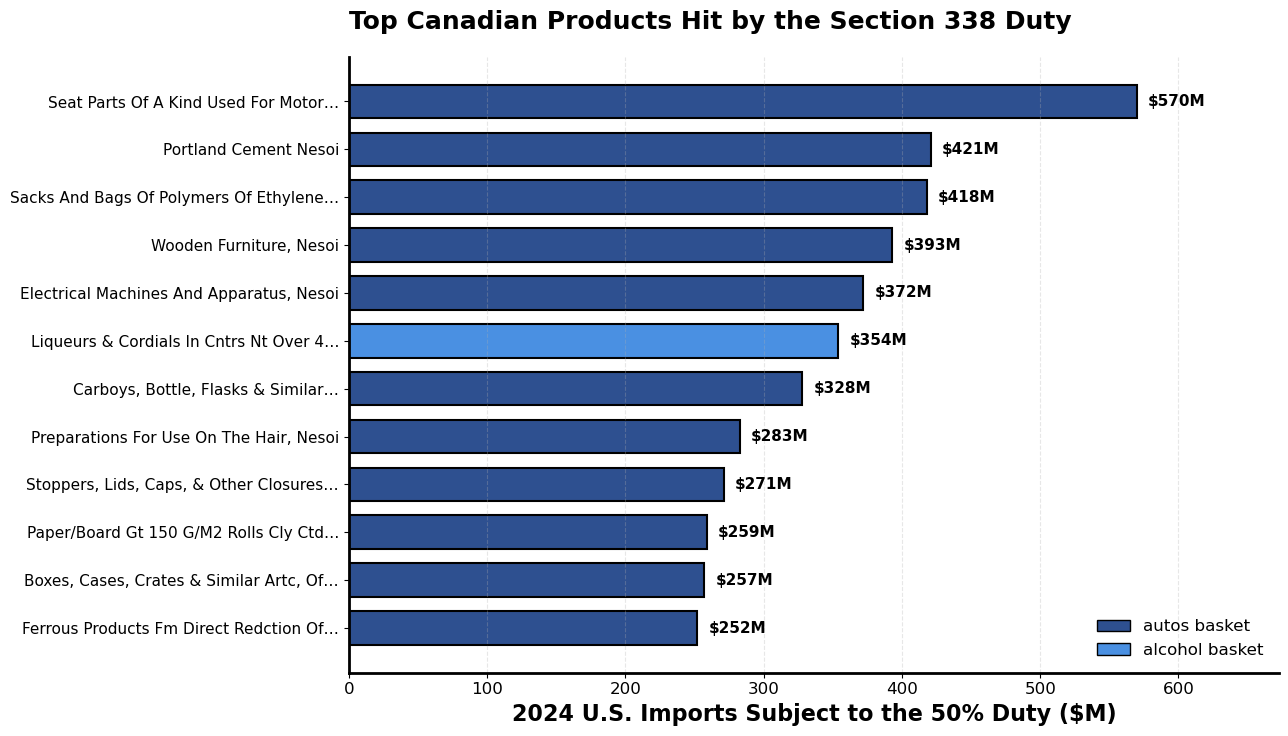

In [10]:
fig, ax = plt.subplots(figsize=(12, 8))

plot_top = top.head(12).iloc[::-1]
def _short(desc, width=42):
    # Truncate to a word boundary so labels do not end mid-word.
    d = desc.title().replace(',', ', ').replace('&', ' & ')
    d = ' '.join(d.split())
    if len(d) <= width:
        return d
    return d[:width].rsplit(' ', 1)[0].rstrip(',') + '…'

labels = [_short(d) for d in plot_top['I_COMMODITY_SDESC']]
bcolor = {'autos': PALETTE['rank1'], 'alcohol': PALETTE['rank2'], 'dairy': PALETTE['tertiary']}

y = np.arange(len(plot_top))
ax.barh(y, plot_top['$M'], 0.7,
        color=[bcolor[b] for b in plot_top['basket']],
        edgecolor='black', linewidth=1.5)

for yi, v in zip(y, plot_top['$M']):
    ax.text(v + 8, yi, f'${v:,.0f}M', va='center', fontsize=11, fontweight='bold')

ax.set_yticks(y)
ax.set_yticklabels(labels, fontsize=11)
ax.set_xlabel(f'{WEIGHT_YEAR} U.S. Imports Subject to the 50% Duty ($M)',
              fontsize=16, fontweight='bold')
ax.set_title('Top Canadian Products Hit by the Section 338 Duty',
             fontsize=18, fontweight='bold', pad=20, loc='left')
ax.set_xlim([0, plot_top['$M'].max() * 1.18])
ax.spines['left'].set_linewidth(2)
ax.spines['bottom'].set_linewidth(2)
ax.grid(axis='x', alpha=0.3, linestyle='--')

from matplotlib.patches import Patch
ax.legend(handles=[Patch(facecolor=bcolor[b], edgecolor='black', label=f'{b} basket')
                   for b in ['autos', 'alcohol']],
          fontsize=12, frameon=False, loc='lower right')

plt.savefig(figfile + 'canada-338-top-products.png', bbox_inches='tight')
plt.savefig(figfile + 'canada-338-top-products.pdf', bbox_inches='tight')
plt.show()

## Section 5 — Impact on Canada's effective tariff rate

The headline number is **+1.85pp**, but the naive figure — 50% applied to
everything in the three baskets — is +2.49pp. The two carve-outs account for the
difference, and it is worth seeing them separately because they are very
different in character.

In [11]:
def pp(mask):
    return 50 * imports.loc[mask, 'imports'].sum() / total_imports

steps = pd.DataFrame([
    {'step': 'All basket goods at 50%',   'pp': pp(in_scope)},
    {'step': 'less Section 232, 51(c)',   'pp': -pp(in_scope & mask_232)},
    {'step': 'less civil aircraft, 51(d)', 'pp': -pp(in_scope & ~mask_232 & mask_air)},
    {'step': 'Modeled rate impact',        'pp': pp(dutied)},
]).set_index('step')

# Confirm the decomposition reproduces the panel step exactly.
before = tariff_imports(load_imports(CANADA, year=WEIGHT_YEAR), CANADA, 0.0,
                        pd.to_datetime('2026-08-18'))
after = tariff_imports(load_imports(CANADA, year=WEIGHT_YEAR), CANADA, 0.0,
                       pd.to_datetime('2026-08-22'))
r0 = (before['tariff'] * before['share']).sum()
r1 = (after['tariff'] * after['share']).sum()

print(f"engine: {r0:.3f}% -> {r1:.3f}%   step = +{r1-r0:.3f}pp")
print(f"decomposition total                  = +{steps.loc['Modeled rate impact','pp']:.3f}pp")
steps.round(3)

engine: 5.817% -> 7.665%   step = +1.848pp
decomposition total                  = +1.848pp


,pp
step,
All basket goods at 50%,2.485
"less Section 232, 51(c)",-0.198
"less civil aircraft, 51(d)",-0.439
Modeled rate impact,1.848


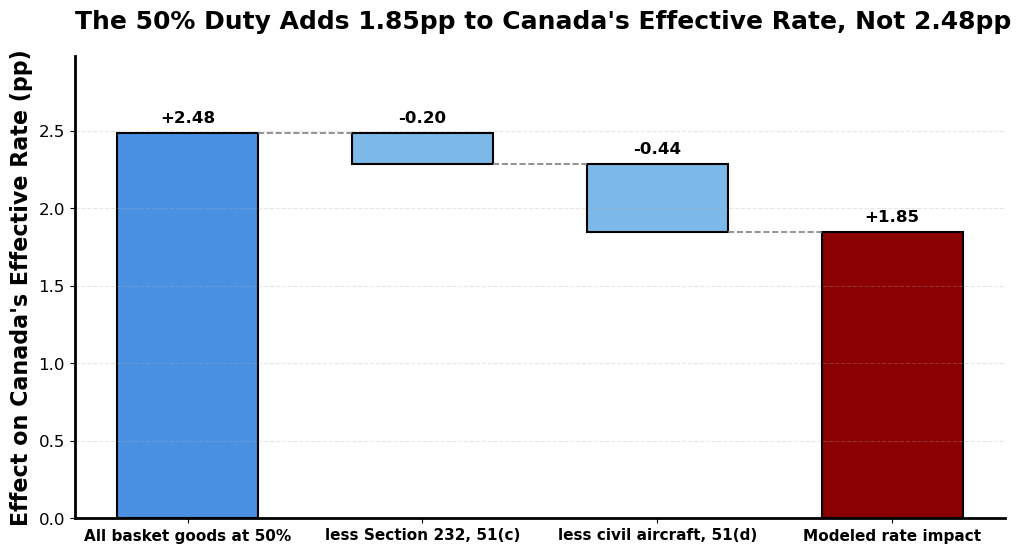

In [12]:
fig, ax = plt.subplots(figsize=(12, 6))

vals = steps['pp'].values
starts = [0, vals[0], vals[0] + vals[1], 0]
heights = [vals[0], vals[1], vals[2], vals[3]]
colors = [PALETTE['rank2'], PALETTE['rank3'], PALETTE['rank3'], PALETTE['secondary']]

x = np.arange(len(steps))
ax.bar(x, heights, 0.6, bottom=starts, color=colors,
       edgecolor='black', linewidth=1.5)

for xi, (s, h) in enumerate(zip(starts, heights)):
    top_y = s + h if h > 0 else s
    ax.text(xi, top_y + 0.05, f'{h:+.2f}', ha='center', va='bottom',
            fontsize=12, fontweight='bold')

# Connectors between the waterfall steps.
for xi in range(3):
    ax.plot([xi + 0.3, xi + 0.7], [starts[xi] + heights[xi]] * 2,
            color='gray', linewidth=1.2, linestyle='--')

ax.set_xticks(x)
ax.set_xticklabels(steps.index, fontsize=11)
for label in ax.get_xticklabels():
    label.set_fontweight('bold')

ax.set_ylabel('Effect on Canada\'s Effective Rate (pp)', fontsize=16, fontweight='bold')
ax.set_title('The 50% Duty Adds 1.85pp to Canada\'s Effective Rate, Not 2.48pp',
             fontsize=18, fontweight='bold', pad=20, loc='left')
ax.set_ylim([0, vals[0] * 1.2])
ax.spines['left'].set_linewidth(2)
ax.spines['bottom'].set_linewidth(2)
ax.grid(axis='y', alpha=0.3, linestyle='--')

plt.savefig(figfile + 'canada-338-rate-decomposition.png', bbox_inches='tight')
plt.savefig(figfile + 'canada-338-rate-decomposition.pdf', bbox_inches='tight')
plt.show()

## Section 6 — Known biases

One modeling gap remains in these baskets, and it is worth stating clearly what
is *not* a bias.

**The auto-parts list, applied flat — biases the rate *down*.** The Proclamation
10908 parts list itself names some provisions at six digits, including 8537.10, but
the Section 232 duty reaches only goods that are parts of passenger vehicles and
light trucks. Whether a good is a car part cannot be resolved from HS10 data, so
`_mask_auto` applies the list to every good in a listed provision. Because Phase 3
carves out Section 232 goods, every good under HS8 8537.10.91 — industrial
switchgear, panelboards, programmable controllers — is treated as an exempt auto
part. Note 51(c)(3) exempts only parts *of passenger vehicles and light trucks*, so
most of this value should be dutiable. This understates Canada's rate from Aug 22 to
Sep 14; from Sep 15 the autos basket stacks on Section 232 and these goods pay the
duty.

**Chapter 44 wood is *not* a bias.** Note 51(c)(4) exempts only wood in the
Section 232 timber headings (9903.76.*): softwood lumber (4403/4406/4407),
upholstered furniture (9401.61) and completed cabinets (9403). The 64 chapter-44
codes in the autos basket are hardwood, plywood, fiberboard and joinery — none of
it covered by Proclamation 10976 — so it is correctly dutiable at 50%. Now that
the timber sector is modeled, the only timber good touching a 338 basket is a
single cabinet line (9403.60.8093), correctly carved out through Sep 14 (its rate
moves from the basket's 50% to the timber 232 rate of 25%). An earlier version of this notebook
counted the 64 ch44 codes as a ~0.16pp upward bias; that was a misdiagnosis,
corrected Jul 23, 2026 when the timber sector was modeled.

In [13]:
# The one real modeling bias in these baskets is the auto-parts list applied flat
# by HS code, which over-exempts switchgear under 8537.10.91 (understates the rate). The
# chapter-44 wood in the basket is hardwood/plywood/joinery — NOT in the Proc
# 10976 Section 232 timber headings — so it is correctly dutiable, not a bias.
switch = in_scope & (imports['HS8'] == '85371091')
ch44   = dutied & (imports['HS8'].str[:2] == '44')   # correctly dutiable, for context

print(f"modeled rate impact                   : +{pp(dutied):.3f}pp")
print(f"correcting the one real bias (mask)   : +{pp(dutied) + pp(switch):.3f}pp")
print()
print(f"HS8 8537.10.91 wrongly exempted       : "
      f"${imports.loc[switch, 'imports'].sum() / 1e9:.3f}B, "
      f"understates by {pp(switch):.3f}pp")
print(f"ch44 wood in basket (dutied, non-232) : "
      f"${imports.loc[ch44, 'imports'].sum() / 1e9:.3f}B across "
      f"{imports.loc[ch44, 'HS8'].nunique()} codes — correctly at 50%")

pd.DataFrame([
    {'item': 'HS8 8537.10.91 exempted as an auto part (list applied flat, over-exempts)',
     'status': 'understates', '$B': imports.loc[switch, 'imports'].sum() / 1e9,
     'pp': pp(switch)},
    {'item': 'Ch. 44 wood in basket (hardwood/plywood, non-232 — correctly dutiable)',
     'status': 'correct', '$B': imports.loc[ch44, 'imports'].sum() / 1e9,
     'pp': pp(ch44)},
]).set_index('item').round(3)

modeled rate impact                   : +1.848pp
correcting the one real bias (mask)   : +2.042pp

HS8 8537.10.91 wrongly exempted       : $1.600B, understates by 0.194pp
ch44 wood in basket (dutied, non-232) : $1.352B across 63 codes — correctly at 50%


,status,$B,pp
item,,,
"HS8 8537.10.91 exempted as an auto part (list applied flat, over-exempts)",understates,1.600,0.194
"Ch. 44 wood in basket (hardwood/plywood, non-232 — correctly dutiable)",correct,1.352,0.164


## Section 7 — Sep 15: alcohol and autos stack on Section 232

Proclamations 11064 and 11065 (Sep 8, effective Sep 15) did two things at once. They
reshuffled the alcohol and autos baskets, and they rewrote note 51(c) so that its
Section 232 exemption names only the dairy heading. From Sep 15, a good in the
alcohol or autos basket that is also a Section 232 good pays the 50% duty **on top
of** its 232 duty, where before it paid only the 232 duty.

The carve-out change matters only for basket goods that are Section 232 goods. In
the Aug 22 baskets that was essentially switchgear the model treats as auto parts
(Section 6). The Sep 15 autos basket also adds steel structures and aluminum
profiles — goods the old carve-out would have exempted — so the additions and the
carve-out change work together.

The cells below compare Canada's rate on every HS10 line on Sep 14 and Sep 15, using
the full engine, and give each line that moved one reason.

In [14]:
# Canada's rate on every HS10 line the day before and the day of each change,
# from the full engine, so these are the published rates.
def line_rates(date):
    return tariff_imports(load_imports(CANADA, year=WEIGHT_YEAR), CANADA, 0.0,
                          pd.to_datetime(date))['tariff']

lines = imports[['HS10', 'HS8', 'I_COMMODITY_SDESC', 'imports', 'share']].copy()
for d in ('2026-09-14', '2026-09-15', '2026-10-29', '2026-10-30'):
    lines[d] = line_rates(d)

def in_basket(*names):
    m = pd.Series(False, index=imports.index)
    for n in names:
        m |= _mask_stacked_include(imports, n)
    return m

old = in_basket('Canada-338-alcohol', 'Canada-338-autos')
new = in_basket('Canada-338-alcohol-2026-09-15', 'Canada-338-autos-2026-09-15')

# The Section 232 sector each good is modeled under (mask_232 is from Section 2).
lines['sector'] = ''
lines.loc[mask_232 & _mask_timber(imports), 'sector'] = 'Timber'
lines.loc[mask_232 & (_mask_steel(imports) | _mask_alu(imports) | _mask_copper(imports)
                      | _mask_annex_IA(imports) | _mask_annex_IB(imports)
                      | _mask_annex_III(imports)), 'sector'] = 'Steel and aluminum'
lines.loc[mask_232 & _mask_auto(imports), 'sector'] = 'Auto parts (list applied flat)'

REMOVED = 'Removed from the basket'
ADDED = 'Added; not a Section 232 good'
CARVE = 'Already in the basket; carve-out removed'
STACKED = 'Added; pays on top of Section 232'
lines['change'] = ''
lines.loc[old & ~new, 'change'] = REMOVED
lines.loc[~old & new & ~mask_232, 'change'] = ADDED
lines.loc[old & new & mask_232, 'change'] = CARVE
lines.loc[~old & new & mask_232, 'change'] = STACKED
lines['pp'] = (lines['2026-09-15'] - lines['2026-09-14']) * lines['share']

# Every line whose rate moved must have a reason, and the parts must add up to
# the published step.
moved = lines['pp'] != 0
step = canada_daily.loc['2026-09-15'] - canada_daily.loc['2026-09-14']
assert (lines.loc[moved, 'change'] != '').all()
assert abs(lines['pp'].sum() - step) < 1e-6

ORDER = [REMOVED, ADDED, CARVE, STACKED]
sep15 = (lines[moved].groupby('change')
         .agg(hs10_lines=('pp', 'size'), imports_bn=('imports', 'sum'), pp=('pp', 'sum'))
         .reindex(ORDER))
sep15['imports_bn'] /= 1e9
sep15.loc['Sep 15 step'] = sep15.sum()

carve_pp = sep15.loc[[CARVE, STACKED], 'pp'].sum()
reshuffle_pp = sep15.loc[[REMOVED, ADDED], 'pp'].sum()
print(f"Canada: {canada_daily.loc['2026-09-14']:.3f}% -> "
      f"{canada_daily.loc['2026-09-15']:.3f}%   step = +{step:.3f}pp")
print(f"dropping the Section 232 carve-out : +{carve_pp:.3f}pp")
print(f"basket reshuffle on its own        : {reshuffle_pp:+.3f}pp")
sep15.round(3)

Canada: 7.665% -> 7.942%   step = +0.277pp
dropping the Section 232 carve-out : +0.308pp
basket reshuffle on its own        : -0.031pp


,hs10_lines,imports_bn,pp
change,,,
Removed from the basket,9.0,0.923,-0.112
Added; not a Section 232 good,135.0,0.666,0.081
Already in the basket; carve-out removed,4.0,0.920,0.112
Added; pays on top of Section 232,23.0,1.616,0.196
Sep 15 step,171.0,4.126,0.277


With the old carve-out in place, the basket changes on their own would have
*lowered* Canada's rate by 0.03pp: the goods removed ($0.92B — salt, cement, refined
lead, sugars, and whisky and liqueurs over 4 liters, among others; listed at the
end of this section) outweigh the
non-232 goods added ($0.67B). Dropping the carve-out adds 0.31pp.

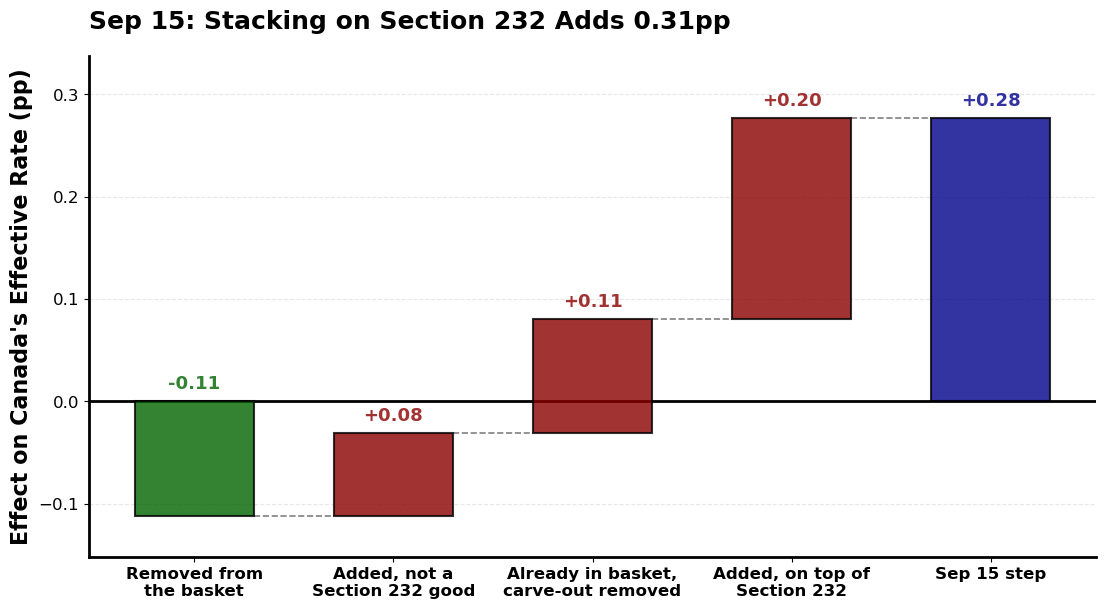

In [15]:
fig, ax = plt.subplots(figsize=(13, 6.5))

vals = sep15.loc[ORDER, 'pp'].values
starts = np.concatenate([[0], np.cumsum(vals)[:-1]])
heights = np.append(vals, vals.sum())
starts = np.append(starts, 0)
colors = [PALETTE['tertiary'] if v < 0 else PALETTE['secondary'] for v in vals] \
         + [PALETTE['primary']]

x = np.arange(len(heights))
bars = ax.bar(x, heights, 0.6, bottom=starts, color=colors, alpha=0.8,
              edgecolor='black', linewidth=1.5, zorder=3)
for b, s, h in zip(bars, starts, heights):
    y = max(s, s + h)
    ax.text(b.get_x() + b.get_width() / 2, y + 0.008, f'{h:+.2f}',
            ha='center', va='bottom', fontsize=13, fontweight='bold',
            color=b.get_facecolor())
for xi in range(len(vals)):
    ax.plot([xi + 0.3, xi + 0.7], [starts[xi] + heights[xi]] * 2,
            color='gray', linewidth=1.2, linestyle='--')
ax.axhline(0, color='black', linewidth=2)

ax.set_xticks(x)
ax.set_xticklabels(['Removed from\nthe basket', 'Added, not a\nSection 232 good',
                    'Already in basket,\ncarve-out removed', 'Added, on top of\nSection 232',
                    'Sep 15 step'], fontsize=12)
for label in ax.get_xticklabels():
    label.set_fontweight('bold')
ax.set_ylabel("Effect on Canada's Effective Rate (pp)", fontsize=16, fontweight='bold')
ax.set_title(f"Sep 15: Stacking on Section 232 Adds {carve_pp:.2f}pp",
             fontsize=18, fontweight='bold', pad=20, loc='left')
ax.set_ylim([min(starts.min(), (starts + heights).min()) - 0.04,
             (starts + heights).max() + 0.06])
ax.grid(axis='y', alpha=0.3, linestyle='--', zorder=0)

plt.savefig(figfile + 'canada-338-sep15-step.png', bbox_inches='tight')
plt.savefig(figfile + 'canada-338-sep15-step.pdf', bbox_inches='tight')
plt.show()

### Which products now stack

Two groups of products account for the whole carve-out effect:

- **Switchgear already in the autos basket** (the four HS10 lines of 8537.10.91 that
  stay in it). The model applies the auto-parts list flat, so it charged these 15% as
  auto parts and exempted them from the 338 duty through Sep 14 (Section 6). From
  Sep 15 they pay both: 65%.
- **Steel and aluminum structures added on Sep 15** (7308.90, 7604). Already at the
  50% metals rate, they now pay 100%. Under the old carve-out, adding them would have
  changed nothing.

In [16]:
# Products whose rate rose because they now pay the 338 duty on top of Section 232.
stack = (lines[moved & lines['change'].isin([CARVE, STACKED])]
         .sort_values('imports', ascending=False)
         .assign(w_before=lambda x: x['imports'] * x['2026-09-14'],
                 w_after=lambda x: x['imports'] * x['2026-09-15']))
stacking = (stack.groupby('HS8', sort=False)
            .agg(product=('I_COMMODITY_SDESC', 'first'), sector=('sector', 'first'),
                 change=('change', 'first'), imports_m=('imports', 'sum'),
                 w_before=('w_before', 'sum'), w_after=('w_after', 'sum'),
                 pp=('pp', 'sum')))
stacking['rate_before'] = stacking.pop('w_before') / stacking['imports_m']
stacking['rate_after'] = stacking.pop('w_after') / stacking['imports_m']
stacking['imports_m'] /= 1e6
stacking = stacking.sort_values('imports_m', ascending=False)
stacking[['product', 'sector', 'change', 'imports_m', 'rate_before', 'rate_after', 'pp']].round(3)

,product,sector,change,imports_m,rate_before,rate_after,pp
HS8,,,,,,,
85371091,"ELECTRICL APP EQP W/ APPS FM 8535&6,LT 1000V,N...",Auto parts (list applied flat),Already in the basket; carve-out removed,920.129,15.0,65.0,0.112
73089095,STRUCTURES AND PARTS ETC NESOI IRON OR STEEL,Steel and aluminum,Added; pays on top of Section 232,586.736,50.0,100.0,0.071
73089030,COLUMNS PILLARS POSTS BEAMS GIRDERS ETC IRN/NA...,Steel and aluminum,Added; pays on top of Section 232,391.432,50.0,100.0,0.048
76042910,"ALUMINUM ALLOY PROF, HEAT-TRTBLE INDSTRL NOT H...",Steel and aluminum,Added; pays on top of Section 232,249.994,50.0,100.0,0.030
76042100,"ALUMINUM ALLOY HOLLOW PROFILES, HEAT TRTABLE I...",Steel and aluminum,Added; pays on top of Section 232,195.797,50.0,100.0,0.024
73089060,COLUMNS PILLARS POSTS BEAMS GIRDERS ETC NESOI,Steel and aluminum,Added; pays on top of Section 232,142.068,50.0,100.0,0.017
76042930,"ALUMINUM ALLOY BAR-ROD HAV ROUND CRS-SECTN, NESOI",Steel and aluminum,Added; pays on top of Section 232,29.381,50.0,100.0,0.004
87032101,PASS MOTOR VEHICLES LT=1000 CC ONLY SPARK IG N...,Steel and aluminum,Added; pays on top of Section 232,10.332,25.0,75.0,0.001
76042950,"ALUMINUM ALLOY, BAR/ROD OTH THAN ROUND C-S, NESOI",Steel and aluminum,Added; pays on top of Section 232,4.643,50.0,100.0,0.001


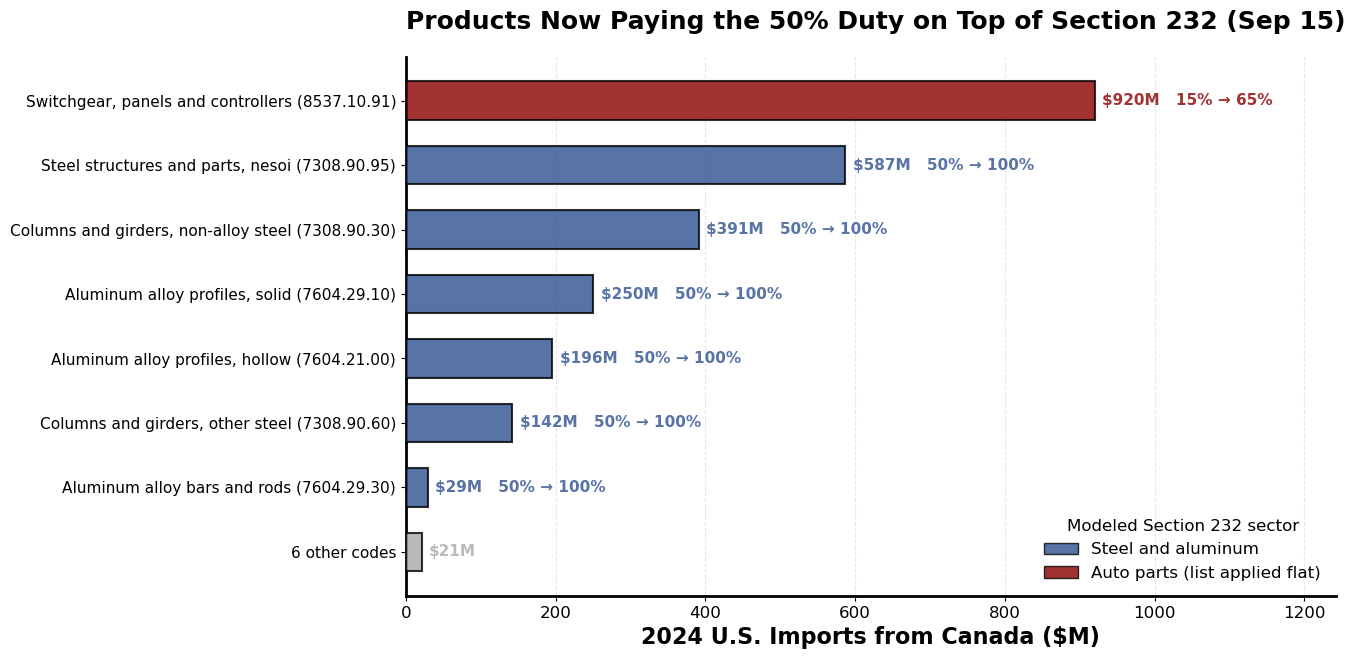

In [17]:
# Chart the largest products and fold the small tail into one bar. Census short
# descriptions are heavily abbreviated, so the charted codes get plain names;
# any code without one falls back to the Census text.
NAMES = {
    '85371091': 'Switchgear, panels and controllers',
    '73089095': 'Steel structures and parts, nesoi',
    '73089030': 'Columns and girders, non-alloy steel',
    '76042910': 'Aluminum alloy profiles, solid',
    '76042100': 'Aluminum alloy profiles, hollow',
    '73089060': 'Columns and girders, other steel',
    '76042930': 'Aluminum alloy bars and rods',
}
N_SHOW = 7
show = stacking.head(N_SHOW)
rest = stacking.iloc[N_SHOW:]
labels = [f"{NAMES.get(h) or _short(p, 30)} ({h[:4]}.{h[4:6]}.{h[6:]})"
          for h, p in zip(show.index, show['product'])] + [f'{len(rest)} other codes']
values = list(show['imports_m']) + [rest['imports_m'].sum()]
rates = [f"{b:.0f}% → {a:.0f}%" for b, a in zip(show['rate_before'], show['rate_after'])] + ['']
SECTOR_COLOR = {'Steel and aluminum': PALETTE['rank1'],
                'Auto parts (list applied flat)': PALETTE['secondary']}
colors = [SECTOR_COLOR[s] for s in show['sector']] + ['#A9A9A9']

fig, ax = plt.subplots(figsize=(12, 7))
y = np.arange(len(values))[::-1]
bars = ax.barh(y, values, 0.6, color=colors, alpha=0.8,
               edgecolor='black', linewidth=1.5, zorder=3)
for b, v, r in zip(bars, values, rates):
    ax.text(v + 10, b.get_y() + b.get_height() / 2,
            f'${v:,.0f}M' + (f'   {r}' if r else ''),
            va='center', fontsize=11, fontweight='bold', color=b.get_facecolor())

ax.set_yticks(y)
ax.set_yticklabels(labels, fontsize=11)
ax.set_xlabel(f'{WEIGHT_YEAR} U.S. Imports from Canada ($M)', fontsize=16, fontweight='bold')
ax.set_title('Products Now Paying the 50% Duty on Top of Section 232 (Sep 15)',
             fontsize=18, fontweight='bold', pad=20, loc='left')
ax.set_xlim([0, max(values) * 1.35])
ax.grid(axis='x', alpha=0.3, linestyle='--', zorder=0)

from matplotlib.patches import Patch
ax.legend(handles=[Patch(facecolor=c, edgecolor='black', alpha=0.8, label=s)
                   for s, c in SECTOR_COLOR.items()],
          title='Modeled Section 232 sector', fontsize=12, title_fontsize=12,
          frameon=False, loc='lower right')

plt.savefig(figfile + 'canada-338-sep15-stacking.png', bbox_inches='tight')
plt.savefig(figfile + 'canada-338-sep15-stacking.pdf', bbox_inches='tight')
plt.show()

### What left the baskets on Sep 15

Ten codes left the alcohol and autos baskets. Five left outright: salt, Portland
cement, chemically pure sugars, tissue stock and refined lead. The other five were
narrowed, each dropping one statistical line: whisky and liqueurs in containers over
4 liters, paper bedsheets, fishing-rod parts, and switchgear assemblies.

Every line that left goes from 50% to 0%, except switchgear assemblies (8537.10.9120,
$680M). The model already exempted those as auto parts (Section 6), so they stay at
the 15% auto-parts rate and leaving the basket changes nothing. Portland cement is
the largest removal: $421M, almost half of the $0.92B that left.

In [18]:
def product_table(df, before, after, by='HS8'):
    """One row per code: largest line's description, imports, value-weighted rates."""
    df = (df.sort_values('imports', ascending=False)
          .assign(w_before=lambda x: x['imports'] * x[before],
                  w_after=lambda x: x['imports'] * x[after]))
    t = (df.groupby(by, sort=False)
         .agg(product=('I_COMMODITY_SDESC', 'first'), imports_m=('imports', 'sum'),
              w_before=('w_before', 'sum'), w_after=('w_after', 'sum'), pp=('pp', 'sum')))
    t['rate_before'] = t.pop('w_before') / t['imports_m']
    t['rate_after'] = t.pop('w_after') / t['imports_m']
    t['imports_m'] /= 1e6
    return t.sort_values('imports_m', ascending=False)

# Listed by HS10: some Sep 15 deletions narrow an HS8 code by dropping single
# statistical lines, so an HS8 total would overstate what left.
removed_sep15 = product_table(lines[moved & (lines['change'] == REMOVED)],
                              '2026-09-14', '2026-09-15', by='HS10')
print(f"{len(removed_sep15)} HS10 lines left the baskets: "
      f"${removed_sep15['imports_m'].sum():,.0f}M, {removed_sep15['pp'].sum():+.3f}pp")
removed_sep15.round(3)

9 HS10 lines left the baskets: $923M, -0.112pp


,product,imports_m,pp,rate_before,rate_after
HS10,,,,,
2523290000,PORTLAND CEMENT NESOI,420.944,-0.051,50.0,0.0
7801100000,"REFINED LEAD, UNWROUGHT",164.736,-0.020,50.0,0.0
4803004000,TOILET/ETC STOCK PPR HSEHLD/SANTRY ROLL/SH OV ...,117.482,-0.014,50.0,0.0
2501000000,"SALT, PURE SODIUM CHLORIDE; SEA WATER",104.623,-0.013,50.0,0.0
4818900080,"BED SHEETS, HOUSEHOLD/HOSPITAL ART. OF PAPER N...",51.821,-0.006,50.0,0.0
2208306085,"WHISKIES, NESOI, CONTAINERS OVER 4 LITERS EACH",38.260,-0.005,50.0,0.0
2940006000,"SUGARS, CHEM PURE (EXC SUCROSE,LACTOSE,ETC) NESOI",13.931,-0.002,50.0,0.0
9507100080,FISHING RODS PARTS AND ACCESSORIES,8.968,-0.001,50.0,0.0
2208700060,LIQUEURS & CORDIALS IN CNTRS OVER 4 LITERS,2.050,-0.000,50.0,0.0


## Section 8 — Oct 30: a swap inside the autos basket

The Proclamation of Oct 23, 2026 (effective Oct 30) changed only the autos basket: it
removed 22 codes and added 100. The rate stays 50%, and note 51(c) is untouched, so
the basket still stacks on Section 232. In value the change is close to a swap:
tariffs fall on $2.32B of 2024 Canadian imports and rise on $2.53B, a net +0.02pp on
Canada's rate.

In [19]:
# Same comparison for Oct 29 vs Oct 30, using the line rates from Section 7. Only
# the autos basket changed.
v2 = in_basket('Canada-338-autos-2026-09-15')
v3 = in_basket('Canada-338-autos-2026-10-30')

FELL = 'Removed from the basket'
NEW = 'Added; not a Section 232 good'
NEW232 = 'Added; pays on top of Section 232'
oct30 = lines[['HS8', 'I_COMMODITY_SDESC', 'imports', 'share', 'sector',
               '2026-10-29', '2026-10-30']].copy()
oct30['change'] = ''
oct30.loc[v2 & ~v3, 'change'] = FELL
oct30.loc[~v2 & v3 & ~mask_232, 'change'] = NEW
oct30.loc[~v2 & v3 & mask_232, 'change'] = NEW232
oct30['pp'] = (oct30['2026-10-30'] - oct30['2026-10-29']) * oct30['share']

# Every line whose rate moved must have a reason, and the parts must add up to
# the published step.
moved30 = oct30['pp'] != 0
step30 = canada_daily.loc['2026-10-30'] - canada_daily.loc['2026-10-29']
assert (oct30.loc[moved30, 'change'] != '').all()
assert abs(oct30['pp'].sum() - step30) < 1e-6

oct30_parts = (oct30[moved30].groupby('change')
               .agg(hs10_lines=('pp', 'size'), imports_bn=('imports', 'sum'), pp=('pp', 'sum'))
               .reindex([FELL, NEW, NEW232]))
oct30_parts['imports_bn'] /= 1e9
oct30_parts.loc['Oct 30 step'] = oct30_parts.sum()
print(f"Canada: {canada_daily.loc['2026-10-29']:.3f}% -> "
      f"{canada_daily.loc['2026-10-30']:.3f}%   step = {step30:+.3f}pp")
oct30_parts.round(3)

Canada: 7.942% -> 7.966%   step = +0.025pp


,hs10_lines,imports_bn,pp
change,,,
Removed from the basket,57.0,2.323,-0.282
Added; not a Section 232 good,121.0,2.499,0.304
Added; pays on top of Section 232,12.0,0.027,0.003
Oct 30 step,190.0,4.850,0.025


### Where tariffs fell

Every removed product goes from 50% to 0%. The removals are mostly **packaging and
the machinery that handles it**: plastic sacks, bags, boxes and crates; corrugated
cartons and paper sacks; polypropylene film; and packing, wrapping and bag-filling
machines. Thin plywood, industrial heat-treatment equipment, molded pulp, seaweed and
produce-sorting machines also leave.

Two removed codes change nothing in the model. Refrigerating equipment (8418.69.01)
and articles of paper pulp (4823.90.10) are on the civil-aircraft carve-out list,
which the model applies flat, so they were already at 0%.

In [20]:
fell = product_table(oct30[moved30 & (oct30['change'] == FELL)], '2026-10-29', '2026-10-30')
new_goods = product_table(oct30[moved30 & oct30['change'].isin([NEW, NEW232])],
                          '2026-10-29', '2026-10-30')
print(f"tariffs fell on {len(fell)} products (${fell['imports_m'].sum() / 1e3:.2f}B); "
      f"{len(new_goods)} products are new (${new_goods['imports_m'].sum() / 1e3:.2f}B)")
fell.round(3)

tariffs fell on 20 products ($2.32B); 78 products are new ($2.53B)


,product,imports_m,pp,rate_before,rate_after
HS8,,,,,
39232100,"SACKS AND BAGS OF POLYMERS OF ETHYLENE, NESOI",675.878,-0.082,50.0,0.0
84224091,"PACKING OR WRAPPING MACHINERY, NESOI",301.016,-0.037,50.0,0.0
39231090,"BOXES,CASES,CRATES&SIMILAR ARTC,OF PLASTIC NESOI",256.685,-0.031,50.0,0.0
48191000,"CARTONS/BOXES/CASES OF CORRUGATED PPR/PBRD, NESOI",220.428,-0.027,50.0,0.0
39202000,"PLATES,SHEETS,ETC,NONCELL, NOT REIN,POLM PROPY...",148.654,-0.018,50.0,0.0
48194000,"SHIPPING SACK/MULTIWALL BAG BASE WIDTH <40CM,P...",148.339,-0.018,50.0,0.0
84223091,"MACHINES FOR OPENING, FILLING AND CLOSING BAGS",143.995,-0.017,50.0,0.0
84198995,"IND MAC,PLANT,EQUIP,TREAT OF MATERL,TEMP CHG,N...",131.548,-0.016,50.0,0.0
44123332,PLYWD OUTER PLY SLCT NCFS SHT WD ONLY NT SRFCE...,108.263,-0.013,50.0,0.0


### What is new

Every added product goes from 0% to 50%, except the window air conditioners and
electric hand tools that are also Section 232 goods, which go from 25% to 75%. The
value is concentrated in **chemicals and consumer products** — diagnostic and lab
reagents, detergents, shampoo, caulk, paints and polyurethanes — along with
electro-surgical instruments, steel valves, coated and printing paper, and wood
flooring.

The goods the announcement led with barely register in Canadian trade. The carpets
and rugs add $8M, the cocoa-powder lines carried no 2024 imports, and chest freezers
(8418.30) are on the civil-aircraft carve-out list, so the model leaves them at 0%.
Of the 100 added codes, 21 carried no 2024 imports from Canada.

In [21]:
new_goods.head(15).round(3)

,product,imports_m,pp,rate_before,rate_after
HS8,,,,,
38221900,"DIAGNOSTIC OR LABORATORY REAGENTS, NESOI",482.493,0.059,0.0,50.0
90189060,ELECTRO-SURGICAL INSTRUMENTS & APPLIANCES & PARTS,185.315,0.023,0.0,50.0
34025051,"SURFACE-ACTIVE PREPARATIONS FOR RETAIL SALE, N...",160.779,0.020,0.0,50.0
32141000,CAULKING COMPOUNDS,125.380,0.015,0.0,50.0
39095010,"POLYURETHANES,ELASTOMERIC",119.997,0.015,0.0,50.0
84818030,"GATE TYPE TAPS, COCKS AND VALVES, STEEL, HD OP",109.323,0.013,0.0,50.0
33051000,SHAMPOOS,105.215,0.013,0.0,50.0
48115940,"PPR/PBRD NESOI CTD/IMPG/COV PLSTC WT<150G/M2, ...",105.188,0.013,0.0,50.0
34039900,"LUBRICATING PREPS,NOT CONT PETROLEUM OILS,NESOI",90.812,0.011,0.0,50.0


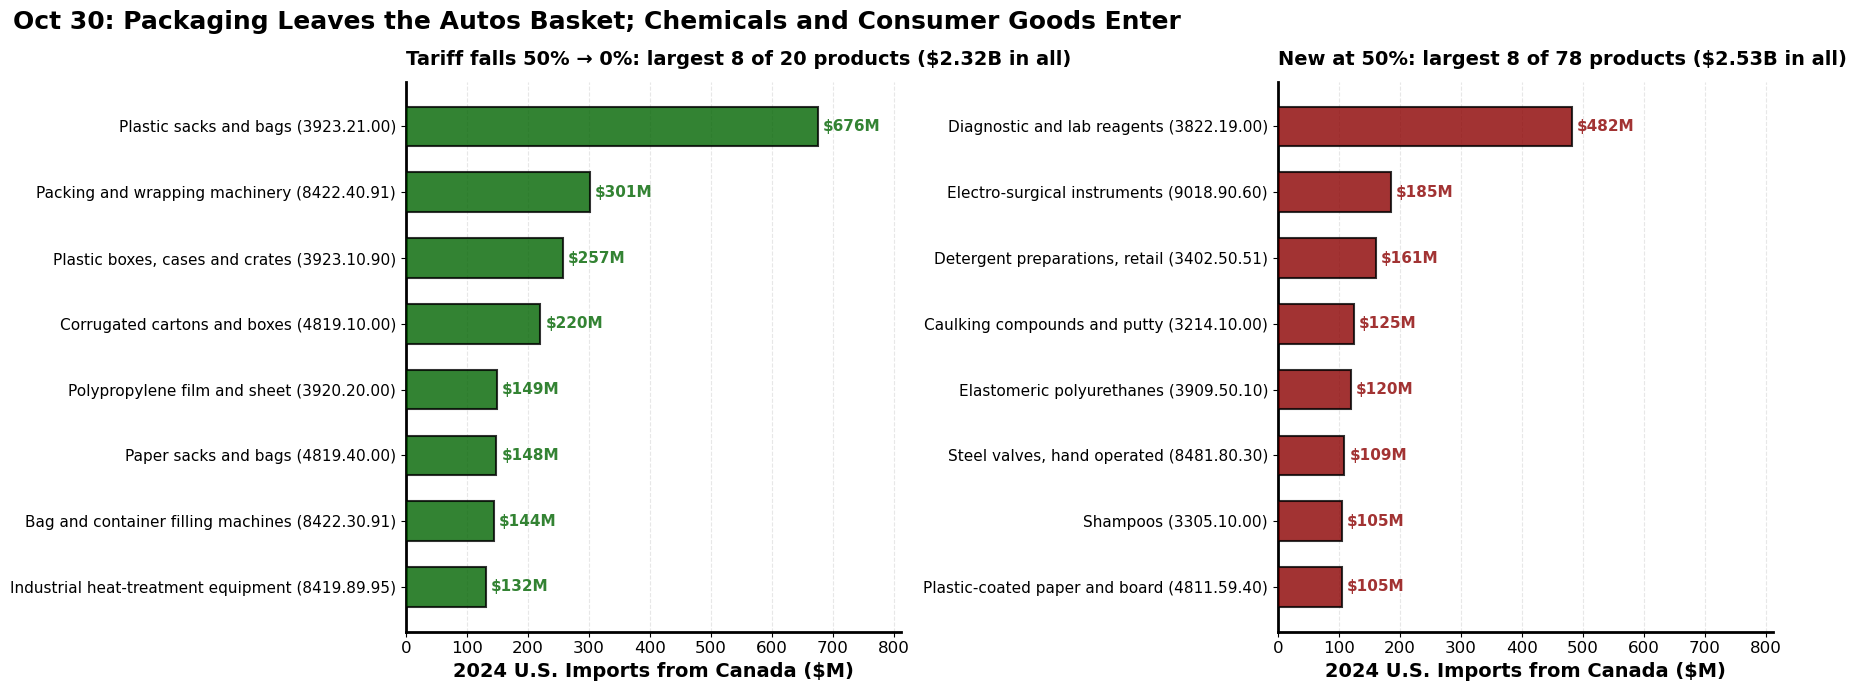

In [22]:
# The largest products on each side, on the same scale. Census short descriptions
# are heavily abbreviated, so the charted codes get plain names; any code without
# one falls back to the Census text.
FELL_NAMES = {
    '39232100': 'Plastic sacks and bags',
    '84224091': 'Packing and wrapping machinery',
    '39231090': 'Plastic boxes, cases and crates',
    '48191000': 'Corrugated cartons and boxes',
    '39202000': 'Polypropylene film and sheet',
    '48194000': 'Paper sacks and bags',
    '84223091': 'Bag and container filling machines',
    '84198995': 'Industrial heat-treatment equipment',
}
NEW_NAMES = {
    '38221900': 'Diagnostic and lab reagents',
    '90189060': 'Electro-surgical instruments',
    '34025051': 'Detergent preparations, retail',
    '32141000': 'Caulking compounds and putty',
    '39095010': 'Elastomeric polyurethanes',
    '84818030': 'Steel valves, hand operated',
    '33051000': 'Shampoos',
    '48115940': 'Plastic-coated paper and board',
}
N_SIDE = 8

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(18, 7), sharex=True)
for ax, t, names, color, what in [
        (ax1, fell, FELL_NAMES, PALETTE['tertiary'], 'Tariff falls 50% → 0%'),
        (ax2, new_goods, NEW_NAMES, PALETTE['secondary'], 'New at 50%')]:
    top = t.head(N_SIDE)
    y = np.arange(len(top))[::-1]
    bars = ax.barh(y, top['imports_m'], 0.6, color=color, alpha=0.8,
                   edgecolor='black', linewidth=1.5, zorder=3)
    for b, v in zip(bars, top['imports_m']):
        ax.text(v + 8, b.get_y() + b.get_height() / 2, f'${v:,.0f}M',
                va='center', fontsize=11, fontweight='bold', color=b.get_facecolor())
    ax.set_yticks(y)
    ax.set_yticklabels([f"{names.get(h) or _short(p, 30)} ({h[:4]}.{h[4:6]}.{h[6:]})"
                        for h, p in zip(top.index, top['product'])], fontsize=11)
    ax.set_title(f"{what}: largest {len(top)} of {len(t)} products "
                 f"(${t['imports_m'].sum() / 1e3:.2f}B in all)",
                 fontsize=14, pad=12, loc='left')
    ax.set_xlabel(f'{WEIGHT_YEAR} U.S. Imports from Canada ($M)', fontsize=14, fontweight='bold')
    ax.grid(axis='x', alpha=0.3, linestyle='--', zorder=0)
ax1.set_xlim([0, max(fell['imports_m'].max(), new_goods['imports_m'].max()) * 1.2])
fig.suptitle('Oct 30: Packaging Leaves the Autos Basket; Chemicals and Consumer Goods Enter',
             fontsize=18, fontweight='bold', x=0.01, ha='left')
fig.tight_layout()

plt.savefig(figfile + 'canada-338-oct30-swap.png', bbox_inches='tight')
plt.savefig(figfile + 'canada-338-oct30-swap.pdf', bbox_inches='tight')
plt.show()

## Summary

- The three Section 338 actions reach **4.97%** of U.S. imports from Canada, and
  after the note 51 carve-outs **3.70%** ($15.2B) actually pays the 50% duty.
- The effect on Canada's effective rate is **+1.85pp**, from 5.82% to 7.66% on
  August 22, 2026. (Both levels sit ~0.18pp higher than before the Section 232
  timber action was modeled, which lifts Canada's whole curve; the *step* is
  essentially unchanged.)
- The motor-vehicle basket carries **93%** of that; alcohol and dairy together
  add 0.13pp.
- The civil-aircraft carve-out removes more than twice as much as the Section 232
  carve-out (0.44pp vs 0.20pp) — the baskets were drafted to avoid Section 232
  goods almost entirely, so that carve-out has little left to do.
- One known bias remains: applying the auto-parts list flat by HS code
  over-exempts switchgear under 8537.10.91, **understating** the rate by ~0.19pp; correcting it would move
  the estimate to about **+2.04pp**. The chapter-44 wood in the basket is *not* a
  bias — it is hardwood/plywood/joinery outside the Proclamation 10976 timber
  headings and is correctly dutiable.
- **Sep 15 (Section 7).** Canada's rate rises to **7.94%** (+0.28pp). Dropping the
  Section 232 carve-out for alcohol and autos is worth **+0.31pp**: +0.11pp on
  switchgear already in the basket (15% → 65%) and +0.20pp on steel structures and
  aluminum profiles added the same day (50% → 100%). The basket reshuffle on its own
  is −0.03pp; Portland cement ($421M) is the largest removal. From Sep 15 the
  switchgear bias no longer applies.
- **Oct 30 (Section 8).** Canada's rate rises to **7.97%** (+0.02pp), close to a swap.
  Tariffs fall from 50% to 0% on $2.32B of packaging, packing machinery, plywood and
  industrial equipment, and rise from 0% to 50% on $2.53B of mostly chemicals and
  consumer products (lab reagents, detergents, shampoo, caulk, paints), surgical
  instruments, valves and paper. Carpets add $8M, and the cocoa-powder lines carried no
  2024 trade.

None of the proclamations carry an expiration date, and note 51 provides no
in-transit grace window, so the August 22 step (deferred from August 19 by Proclamation 11056) is modeled as a clean cliff.